<a href="https://colab.research.google.com/github/MatheusMacagnan/AulaPythonFaculdade/blob/Matheus_Alves_Macagnan/aula_13/Matheus_Macagnan_Aula_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Atividade 1

In [ ]:
import pandas as pd
import numpy as np

# Carregando a base de dados
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Base de dados carregada com sucesso!")

# Visualizando as primeiras linhas
print(df.head())

# Verificando informações da base
df.info()

# Verificando valores ausentes
print(df.isnull().sum())

# Removendo registros duplicados
df = df.drop_duplicates()

# Removendo dados inconsistentes
df = df[df['age'] >= 0]
df = df[df['fare'] >= 0]

# Preenchendo valores ausentes da idade com a média
df['age'] = df['age'].fillna(df['age'].mean())

# Preenchendo valores ausentes do embarque com o mais frequente
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

# Removendo registros sem informação de sobrevivência
df = df.dropna(subset=['survived'])

print("\nDados tratados com sucesso!")

# Verificando novamente os valores ausentes
print(df.isnull().sum())

# Criando um filtro
df_filtrado = df[(df['survived'] == 1) & (df['age'] >= 18)]

# Salvando o novo DataFrame em CSV
df_filtrado.to_csv('titanic_limpo.csv', index=False)

print("Arquivo CSV exportado com sucesso!")

# Visualizando os dados filtrados
print(df_filtrado.head())

Base de dados carregada com sucesso!
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -

Atividade 2

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         1       1  female  38.0      1      0  71.2833        C  First   
1         1       3  female  26.0      0      0   7.9250        S  Third   
2         1       1  female  35.0      1      0  53.1000        S  First   
3         1       3  female  27.0      0      2  11.1333        S  Third   
4         1       1  female  58.0      0      0  26.5500        S  First   

     who  adult_male deck  embark_town alive  alone  
0  woman       False    C    Cherbourg   yes  False  
1  woman       False  NaN  Southampton   yes   True  
2  woman       False    C  Southampton   yes  False  
3  woman       False  NaN  Southampton   yes  False  
4  woman       False    C  Southampton   yes   True  


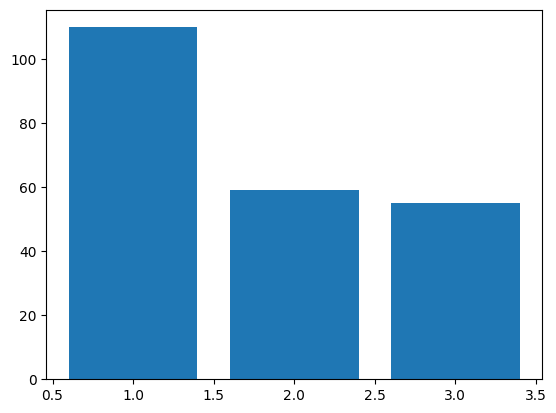

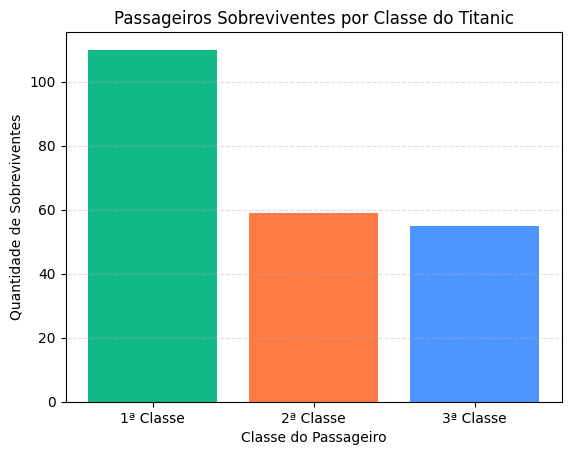

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Importando a base de dados limpa
df = pd.read_csv('titanic_limpo.csv')

# Visualizando os primeiros registros
print(df.head())

# Contando passageiros sobreviventes por classe
sobreviventes = df['pclass'].value_counts().sort_index()

# Criando o gráfico de barras
plt.bar(sobreviventes.index, sobreviventes.values)

# Exibindo o gráfico
plt.show()

# Criando o gráfico
plt.bar(
    sobreviventes.index,
    sobreviventes.values,
    color=['#12B886', '#FF7A45', '#4D96FF']
)

# Adicionando título
plt.title('Passageiros Sobreviventes por Classe do Titanic')

# Nomeando os eixos
plt.xlabel('Classe do Passageiro')
plt.ylabel('Quantidade de Sobreviventes')

# Ajustando os marcadores do eixo X
plt.xticks([1, 2, 3], ['1ª Classe', '2ª Classe', '3ª Classe'])

# Adicionando uma grade para facilitar a leitura
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Exibindo o gráfico
plt.show()